

---
<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL


                    
---

### PROJECT INFORMATION
- **Project Title:** Phân Tích Dữ Liệu Các Yếu Tố Ảnh Hưởng Đến Kết Quả Học Tập Của Sinh Viên

- **Class Code:** AI2107
- **Group Name/ID:** Group 6
- **Member List:**
  1. Lê Gia Bảo - HE204387
  2. Nguyễn Trần Xuân Bắc - HE201951
  3. Tô Văn Quang - HE204351
- **Submission Date:** 08/11/2026

---
**Mục tiêu:**
1. Tải và mô tả tập dữ liệu
2. Kiểm tra chất lượng dữ liệu (giá trị thiếu, trùng lặp, kiểu dữ liệu, giá trị bất thường)
3. Thực hiện thống kê mô tả
4. Tạo các hình ảnh trực quan có ý nghĩa
5. Nghiên cứu mối quan hệ giữa các biến

**Tập dữ liệu:** `StudentPerformanceFactors.csv` — chứa thông tin về các yếu tố ảnh hưởng đến điểm thi của sinh viên.

## 1. Import thư viện và tải dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print(" Đã import thành công tất cả thư viện!")

 Đã import thành công tất cả thư viện!


In [2]:
import os

# Đọc dữ liệu (tự kiểm tra đường dẫn nếu mở từ thư mục cha)
file_path = 'StudentPerformanceFactors.csv' if os.path.exists('StudentPerformanceFactors.csv') else '4_Source Code/StudentPerformanceFactors.csv'
df = pd.read_csv(file_path)

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng × {df.shape[1]} cột")
print(f"Dung lượng bộ nhớ: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")
print()
print("5 dòng đầu tiên:")
df.head()

Kích thước tập dữ liệu: 6607 dòng × 16 cột
Dung lượng bộ nhớ: 3823.4 KB

5 dòng đầu tiên:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Parental_Education_Level,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Low,Medium,Public,Positive,3,High School,Male,67
1,19,64,Low,Medium,No,8,59,Low,Medium,Medium,Public,Negative,4,College,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Medium,Medium,Public,Neutral,4,Postgraduate,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Medium,Medium,Public,Negative,4,High School,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Medium,High,Public,Neutral,4,College,Female,70


## 2. Mô tả tổng quan tập dữ liệu

In [3]:

print("=" * 70)
print(" THÔNG TIN TỔNG QUAN VỀ TẬP DỮ LIỆU")
print("=" * 70)
print()
df.info()

 THÔNG TIN TỔNG QUAN VỀ TẬP DỮ LIỆU

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Family_Income               6607 non-null   str  
 9   Teacher_Quality             6529 non-null   str  
 10  School_Type                 6607 non-null   str  
 11  Peer_Influence              6607 non-null   str  
 12  Physical_Activity           6607 non-null   int64
 13  Parental_Education_Level    6517 non-

In [4]:
# Phân loại các biến
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

print(" CÁC BIẾN SỐ (Numeric):")
for i, col in enumerate(numeric_cols, 1):
    print(f"   {i}. {col}")

print(f"\n CÁC BIẾN PHÂN LOẠI (Categorical):")
for i, col in enumerate(categorical_cols, 1):
    unique_vals = df[col].dropna().unique()
    print(f"   {i}. {col}: {list(unique_vals)}")

print(f"\n→ Tổng: {len(numeric_cols)} biến số + {len(categorical_cols)} biến phân loại = {len(df.columns)} biến")

 CÁC BIẾN SỐ (Numeric):
   1. Hours_Studied
   2. Attendance
   3. Sleep_Hours
   4. Previous_Scores
   5. Physical_Activity
   6. Exam_Score

 CÁC BIẾN PHÂN LOẠI (Categorical):
   1. Parental_Involvement: ['Low', 'Medium', 'High']
   2. Access_to_Resources: ['High', 'Medium', 'Low']
   3. Extracurricular_Activities: ['No', 'Yes']
   4. Motivation_Level: ['Low', 'Medium', 'High']
   5. Family_Income: ['Low', 'Medium', 'High']
   6. Teacher_Quality: ['Medium', 'High', 'Low']
   7. School_Type: ['Public', 'Private']
   8. Peer_Influence: ['Positive', 'Negative', 'Neutral']
   9. Parental_Education_Level: ['High School', 'College', 'Postgraduate']
   10. Gender: ['Male', 'Female']

→ Tổng: 6 biến số + 10 biến phân loại = 16 biến


## 3. Kiểm tra chất lượng dữ liệu

### 3.1. Giá trị thiếu (Missing Values)

CÁC CỘT CÓ GIÁ TRỊ THIẾU:
                          Số lượng thiếu  Tỷ lệ (%)
Teacher_Quality                       78       1.18
Parental_Education_Level              90       1.36


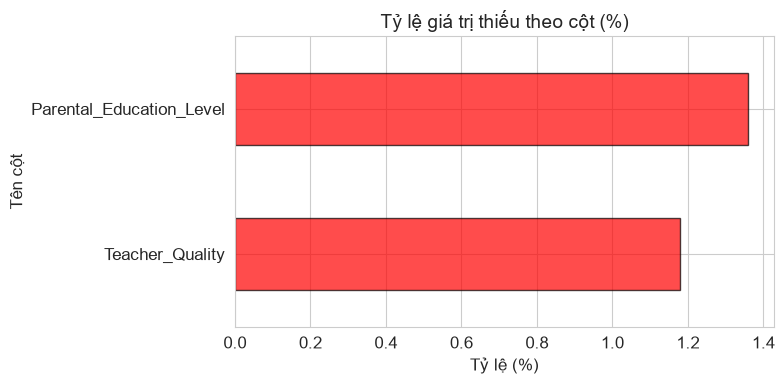

In [5]:
# Kiểm tra giá trị thiếu ở từng cột
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    'Số lượng thiếu': missing_count,
    'Tỷ lệ (%)': missing_percent
})

# Lọc ra các cột có giá trị thiếu
cols_missing = missing_table[missing_table['Số lượng thiếu'] > 0]

print("CÁC CỘT CÓ GIÁ TRỊ THIẾU:")
if len(cols_missing) > 0:
    print(cols_missing)
    
    # Vẽ biểu đồ đơn giản
    plt.figure(figsize=(8, 4))
    cols_missing['Tỷ lệ (%)'].plot(kind='barh', color='red', edgecolor='black', alpha=0.7)
    plt.title('Tỷ lệ giá trị thiếu theo cột (%)')
    plt.xlabel('Tỷ lệ (%)')
    plt.ylabel('Tên cột')
    plt.tight_layout()
    plt.show()
else:
    print("Không có giá trị thiếu trong tập dữ liệu.")

### 3.2. Giá trị trùng lặp (Duplicates)

In [6]:
# Kiểm tra các dòng bị trùng lặp hoàn toàn
dup_count = df.duplicated().sum()
print("Số dòng bị trùng lặp:", dup_count)

if dup_count == 0:
    print("Tập dữ liệu không có dòng trùng lặp.")
else:
    print("Các dòng bị trùng:")
    print(df[df.duplicated()])

Số dòng bị trùng lặp: 0
Tập dữ liệu không có dòng trùng lặp.


### 3.3. Kiểm tra kiểu dữ liệu

In [7]:
# Kiểm tra kiểu dữ liệu của từng cột
print("KIỂU DỮ LIỆU CÁC CỘT:")
print(df.dtypes)

print("\nSố giá trị khác nhau ở mỗi cột:")
print(df.nunique())

print(f"\nTổng số cột dạng số: {len(numeric_cols)}")
print(f"Tổng số cột dạng chữ (phân loại): {len(categorical_cols)}")

KIỂU DỮ LIỆU CÁC CỘT:
Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Parental_Education_Level        str
Gender                          str
Exam_Score                    int64
dtype: object

Số giá trị khác nhau ở mỗi cột:
Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Family_Income                  3
Teacher_Quality                3
School_Type              

### 3.4. Phát hiện giá trị bất thường (Outliers)

KIỂM TRA OUTLIERS BẰNG PHƯƠNG PHÁP IQR:
- Hours_Studied: 43 outliers (0.65%), ngưỡng hợp lệ [4.0, 36.0]
- Attendance: 0 outliers (0.00%), ngưỡng hợp lệ [40.0, 120.0]
- Sleep_Hours: 0 outliers (0.00%), ngưỡng hợp lệ [3.0, 11.0]
- Previous_Scores: 0 outliers (0.00%), ngưỡng hợp lệ [25.5, 125.5]
- Physical_Activity: 0 outliers (0.00%), ngưỡng hợp lệ [-1.0, 7.0]
- Exam_Score: 104 outliers (1.57%), ngưỡng hợp lệ [59.0, 75.0]


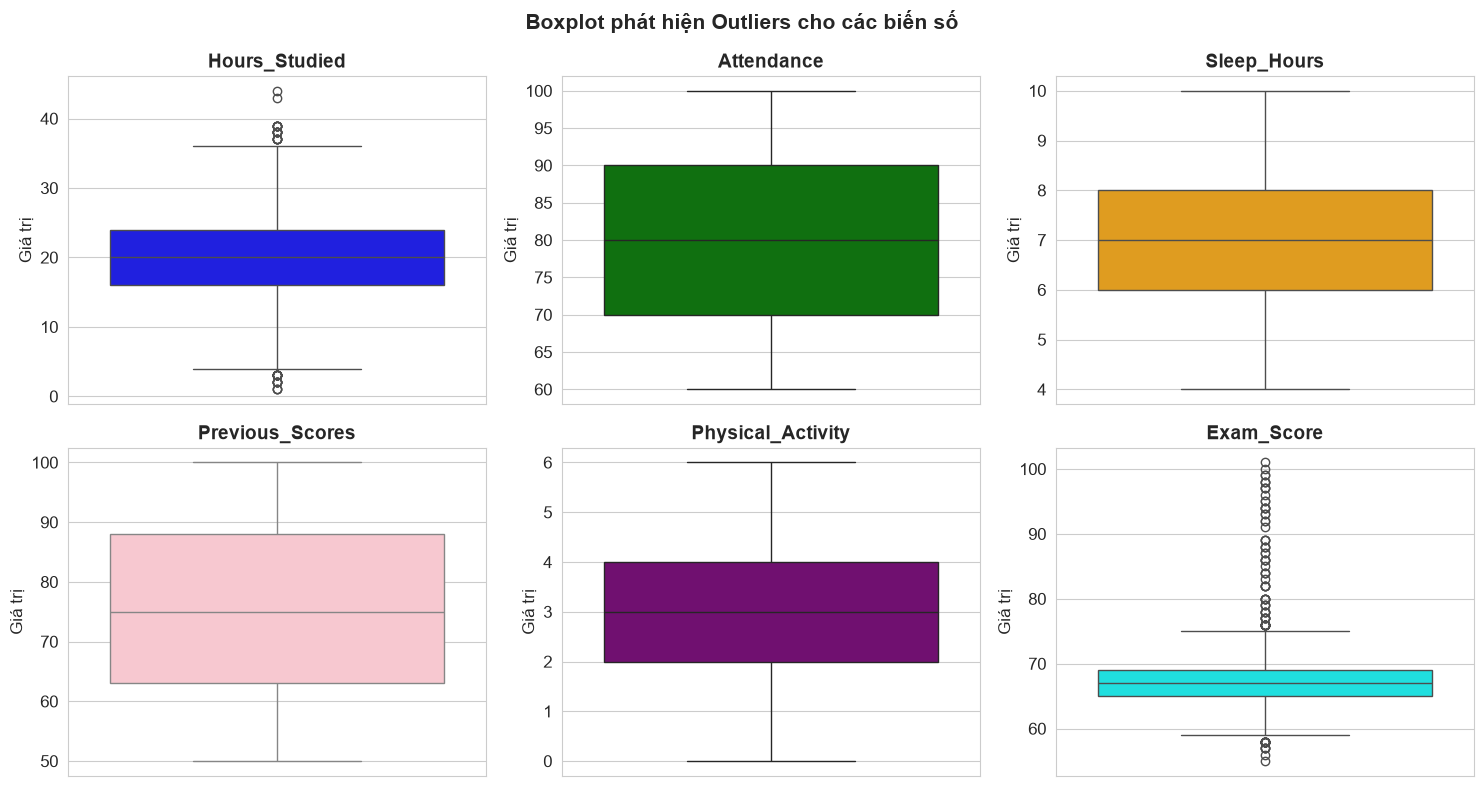

In [8]:
# Phát hiện giá trị bất thường (Outliers) bằng phương pháp IQR
print("KIỂM TRA OUTLIERS BẰNG PHƯƠNG PHÁP IQR:")

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    pct = len(outliers) / len(df) * 100
    print(f"- {col}: {len(outliers)} outliers ({pct:.2f}%), ngưỡng hợp lệ [{lower:.1f}, {upper:.1f}]")

# Vẽ Boxplot cho các biến số
plt.figure(figsize=(15, 8))
box_colors = ['blue', 'green', 'orange', 'pink', 'purple', 'cyan']

for i, col in enumerate(numeric_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col], color=box_colors[i % len(box_colors)])
    plt.title(col, fontweight='bold')
    plt.ylabel('Giá trị')

plt.suptitle('Boxplot phát hiện Outliers cho các biến số', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Thống kê mô tả (Descriptive Statistics)

### 4.1. Thống kê mô tả cho biến số

In [9]:
# Thống kê mô tả cho biến số
print("=" * 80)
print(" THỐNG KÊ MÔ TẢ CHO CÁC BIẾN SỐ")
print("=" * 80)
print()

desc = df[numeric_cols].describe().T
desc['median'] = df[numeric_cols].median()
desc['skew'] = df[numeric_cols].skew().round(3)
desc['kurtosis'] = df[numeric_cols].kurtosis().round(3)
desc = desc[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'skew', 'kurtosis']]
desc.columns = ['Số lượng', 'Trung bình', 'Trung vị', 'Độ lệch chuẩn', 'Min', 'Q1', 'Q2', 'Q3', 'Max', 'Skewness', 'Kurtosis']
print(desc.round(2).to_string())

print("\n Nhận xét:")
for col in numeric_cols:
    skew = df[col].skew()
    if abs(skew) < 0.5:
        dist = "phân phối gần đối xứng"
    elif skew > 0:
        dist = "lệch phải (right-skewed)"
    else:
        dist = "lệch trái (left-skewed)"
    print(f"   • {col}: {dist} (skewness = {skew:.3f})")

 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN SỐ

                   Số lượng  Trung bình  Trung vị  Độ lệch chuẩn   Min    Q1    Q2    Q3    Max  Skewness  Kurtosis
Hours_Studied        6607.0       19.98      20.0           5.99   1.0  16.0  20.0  24.0   44.0      0.01      0.02
Attendance           6607.0       79.98      80.0          11.55  60.0  70.0  80.0  90.0  100.0      0.01     -1.19
Sleep_Hours          6607.0        7.03       7.0           1.47   4.0   6.0   7.0   8.0   10.0     -0.02     -0.50
Previous_Scores      6607.0       75.07      75.0          14.40  50.0  63.0  75.0  88.0  100.0     -0.00     -1.19
Physical_Activity    6607.0        2.97       3.0           1.03   0.0   2.0   3.0   4.0    6.0     -0.03     -0.06
Exam_Score           6607.0       67.24      67.0           3.89  55.0  65.0  67.0  69.0  101.0      1.64     10.58

 Nhận xét:
   • Hours_Studied: phân phối gần đối xứng (skewness = 0.013)
   • Attendance: phân phối gần đối xứng (skewness = 0.014)
   • Sleep_Hours: phân

### 4.2. Thống kê mô tả cho biến phân loại

In [10]:
# Thống kê mô tả cho biến phân loại
print("=" * 70)
print(" THỐNG KÊ MÔ TẢ CHO CÁC BIẾN PHÂN LOẠI")
print("=" * 70)
print()

for col in categorical_cols:
    print(f"\n {col}:")
    counts = df[col].value_counts(dropna=False)
    pcts = df[col].value_counts(normalize=True, dropna=False) * 100
    summary = pd.DataFrame({'Số lượng': counts, 'Tỷ lệ (%)': pcts.round(2)})
    print(summary.to_string())
    print(f"   → Mode: {df[col].mode()[0]}")
    print("-" * 40)

 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN PHÂN LOẠI


 Parental_Involvement:
                      Số lượng  Tỷ lệ (%)
Parental_Involvement                     
Medium                    3362      50.89
High                      1908      28.88
Low                       1337      20.24
   → Mode: Medium
----------------------------------------

 Access_to_Resources:
                     Số lượng  Tỷ lệ (%)
Access_to_Resources                     
Medium                   3319      50.23
High                     1975      29.89
Low                      1313      19.87
   → Mode: Medium
----------------------------------------

 Extracurricular_Activities:
                            Số lượng  Tỷ lệ (%)
Extracurricular_Activities                     
Yes                             3938       59.6
No                              2669       40.4
   → Mode: Yes
----------------------------------------

 Motivation_Level:
                  Số lượng  Tỷ lệ (%)
Motivation_Level                     
Medium

## 5. Trực quan hóa dữ liệu (Data Visualization)

###  Hình 1: Phân phối điểm thi (Exam Score Distribution)

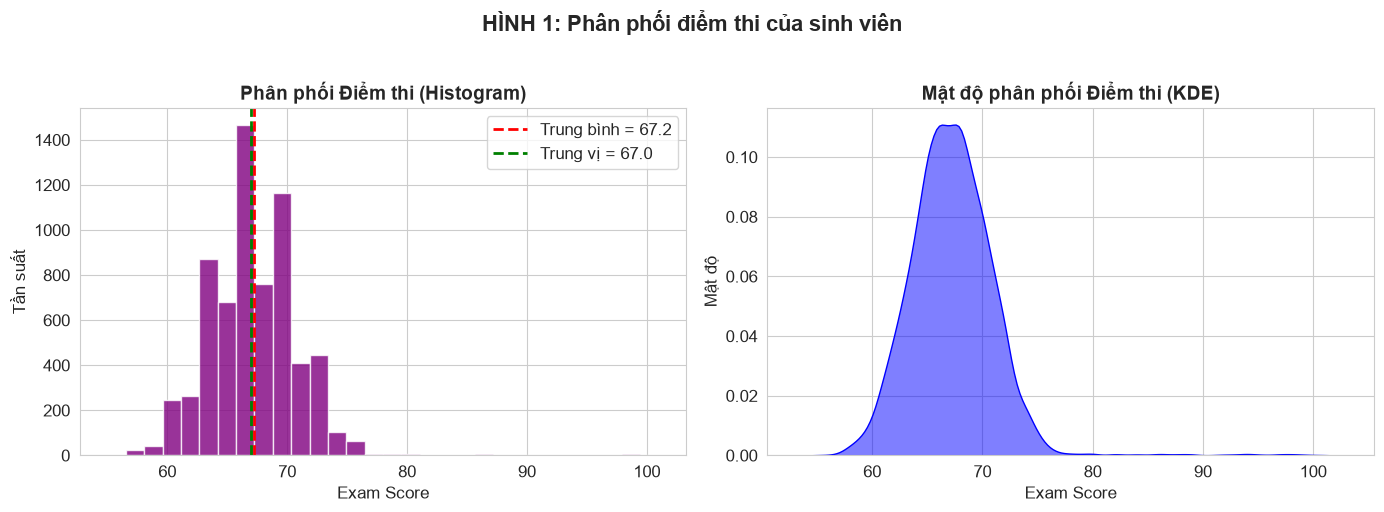


 Nhận xét: Điểm thi có phân phối gần chuẩn với trung bình 67.2 và độ lệch chuẩn 3.9. Điểm dao động từ 55 đến 101.


In [11]:
# HÌNH 1: Phân phối điểm thi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Exam_Score'], bins=30, color='purple', edgecolor='white', alpha=0.8)
axes[0].axvline(df['Exam_Score'].mean(), color='red', linestyle='--', linewidth=2, 
                label=f"Trung bình = {df['Exam_Score'].mean():.1f}")
axes[0].axvline(df['Exam_Score'].median(), color='green', linestyle='--', linewidth=2,
                label=f"Trung vị = {df['Exam_Score'].median():.1f}")
axes[0].set_title('Phân phối Điểm thi (Histogram)', fontweight='bold')
axes[0].set_xlabel('Exam Score')
axes[0].set_ylabel('Tần suất')
axes[0].legend()

# KDE plot
sns.kdeplot(data=df, x='Exam_Score', fill=True, color='blue', alpha=0.5, ax=axes[1])
axes[1].set_title('Mật độ phân phối Điểm thi (KDE)', fontweight='bold')
axes[1].set_xlabel('Exam Score')
axes[1].set_ylabel('Mật độ')

plt.suptitle('HÌNH 1: Phân phối điểm thi của sinh viên', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\n Nhận xét: Điểm thi có phân phối gần chuẩn với trung bình {df['Exam_Score'].mean():.1f} "
      f"và độ lệch chuẩn {df['Exam_Score'].std():.1f}. "
      f"Điểm dao động từ {df['Exam_Score'].min()} đến {df['Exam_Score'].max()}.")

###  Hình 2: Ma trận tương quan (Correlation Heatmap)

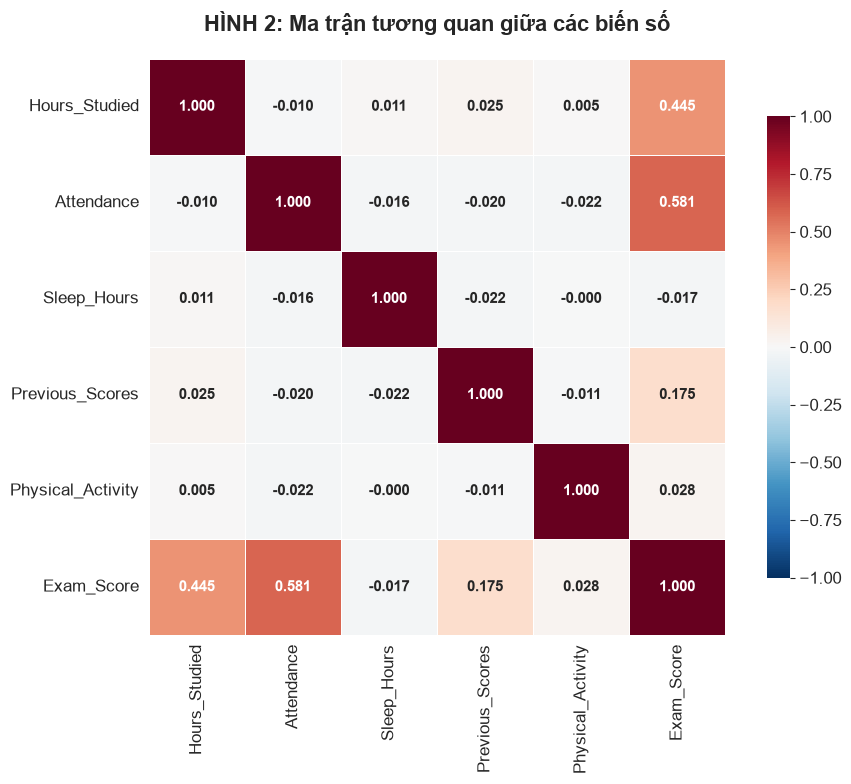


 Nhận xét:
   Mức độ tương quan với Exam_Score (theo thứ tự giảm dần):
   • Attendance: r = 0.581 (tương quan thuận, mạnh)
   • Hours_Studied: r = 0.445 (tương quan thuận, trung bình)
   • Previous_Scores: r = 0.175 (tương quan thuận, yếu)
   • Physical_Activity: r = 0.028 (tương quan thuận, yếu)
   • Sleep_Hours: r = -0.017 (tương quan nghịch, yếu)


In [12]:
# HÌNH 2: Correlation Heatmap
fig, ax = plt.subplots(figsize=(10, 8))

corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot_kws={"size": 11, "fontweight": "bold"}, ax=ax)

ax.set_title('HÌNH 2: Ma trận tương quan giữa các biến số', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n Nhận xét:")
# Tìm cặp biến có tương quan cao nhất với Exam_Score
exam_corr = corr_matrix['Exam_Score'].drop('Exam_Score').abs().sort_values(ascending=False)
print("   Mức độ tương quan với Exam_Score (theo thứ tự giảm dần):")
for var, val in exam_corr.items():
    direction = "thuận" if corr_matrix.loc[var, 'Exam_Score'] > 0 else "nghịch"
    strength = "mạnh" if val > 0.5 else "trung bình" if val > 0.3 else "yếu"
    print(f"   • {var}: r = {corr_matrix.loc[var, 'Exam_Score']:.3f} (tương quan {direction}, {strength})")

###  Hình 3: Ảnh hưởng của các yếu tố phân loại đến Điểm thi

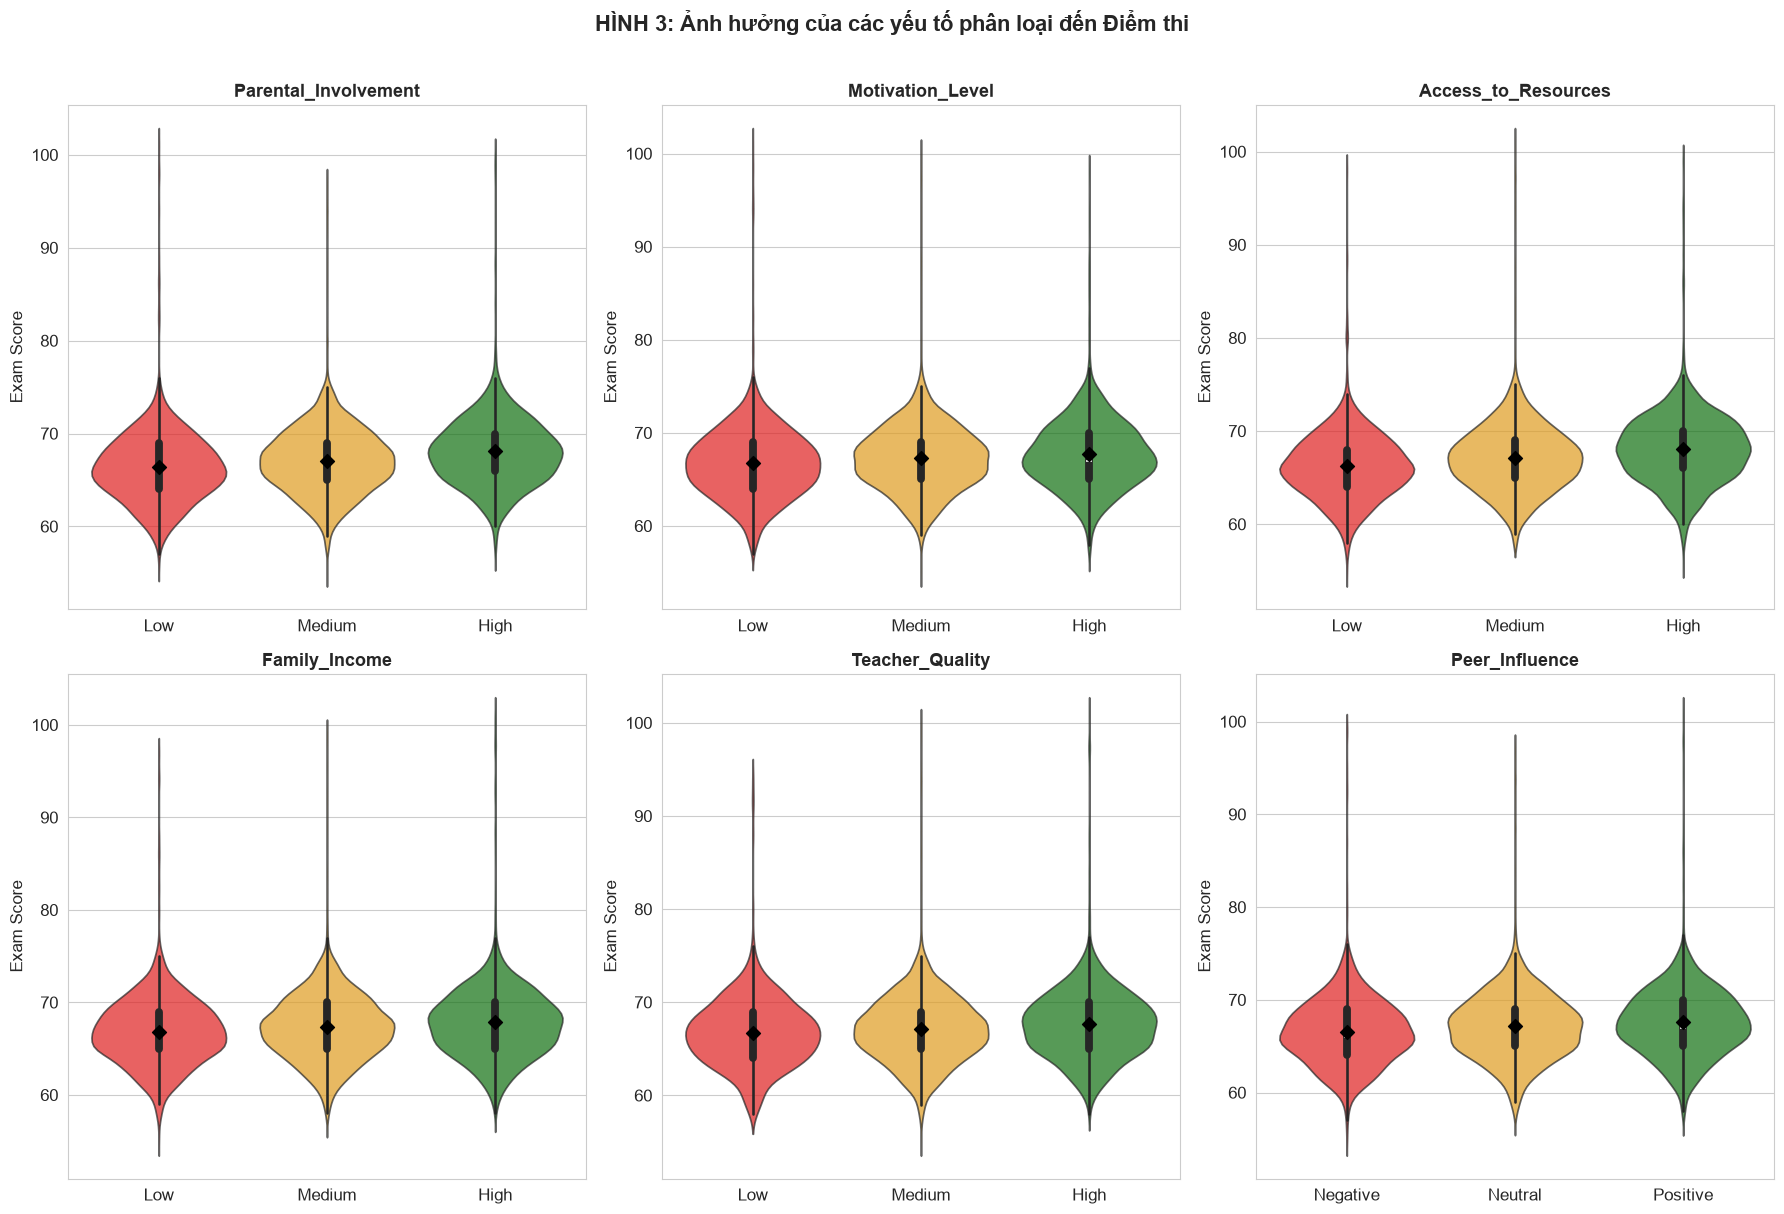


 Nhận xét:
   • Parental_Involvement: Nhóm 'High' có điểm cao nhất (68.09), nhóm 'Low' có điểm thấp nhất (66.36), chênh lệch = 1.73
   • Motivation_Level: Nhóm 'High' có điểm cao nhất (67.7), nhóm 'Low' có điểm thấp nhất (66.75), chênh lệch = 0.95
   • Access_to_Resources: Nhóm 'High' có điểm cao nhất (68.09), nhóm 'Low' có điểm thấp nhất (66.2), chênh lệch = 1.89
   • Family_Income: Nhóm 'High' có điểm cao nhất (67.84), nhóm 'Low' có điểm thấp nhất (66.85), chênh lệch = 0.99
   • Teacher_Quality: Nhóm 'High' có điểm cao nhất (67.68), nhóm 'Low' có điểm thấp nhất (66.75), chênh lệch = 0.93
   • Peer_Influence: Nhóm 'Positive' có điểm cao nhất (67.62), nhóm 'Negative' có điểm thấp nhất (66.56), chênh lệch = 1.06


In [13]:
# HÌNH 3: Violin/Box plots cho các biến phân loại quan trọng
cat_vars = ['Parental_Involvement', 'Motivation_Level', 'Access_to_Resources',
            'Family_Income', 'Teacher_Quality', 'Peer_Influence']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

palette = {'Low': 'red', 'Medium': 'orange', 'High': 'green',
           'Positive': 'green', 'Neutral': 'orange', 'Negative': 'red',
           'Yes': 'green', 'No': 'red'}

for i, col in enumerate(cat_vars):
    order = None
    if col in ['Parental_Involvement', 'Motivation_Level', 'Access_to_Resources', 
               'Family_Income', 'Teacher_Quality']:
        order = ['Low', 'Medium', 'High']
    elif col == 'Peer_Influence':
        order = ['Negative', 'Neutral', 'Positive']
    
    valid_order = [o for o in (order or []) if o in df[col].dropna().unique()]
    
    sns.violinplot(data=df, x=col, y='Exam_Score', order=valid_order if valid_order else None,
                   palette=palette, inner='box', ax=axes[i], alpha=0.7)
    
    # Thêm mean marker
    means = df.groupby(col)['Exam_Score'].mean()
    for j, cat in enumerate(valid_order if valid_order else df[col].dropna().unique()):
        if cat in means.index:
            idx = list(valid_order if valid_order else df[col].dropna().unique()).index(cat)
            axes[i].scatter(idx, means[cat], color='black', s=50, zorder=5, marker='D')
    
    axes[i].set_title(f'{col}', fontweight='bold', fontsize=13)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Exam Score')

plt.suptitle('HÌNH 3: Ảnh hưởng của các yếu tố phân loại đến Điểm thi', 
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("\n Nhận xét:")
for col in cat_vars:
    group_means = df.groupby(col)['Exam_Score'].mean().round(2)
    best = group_means.idxmax()
    worst = group_means.idxmin()
    diff = group_means.max() - group_means.min()
    print(f"   • {col}: Nhóm '{best}' có điểm cao nhất ({group_means[best]}), "
          f"nhóm '{worst}' có điểm thấp nhất ({group_means[worst]}), chênh lệch = {diff:.2f}")

###  Hình 4: Phân phối các biến số chính

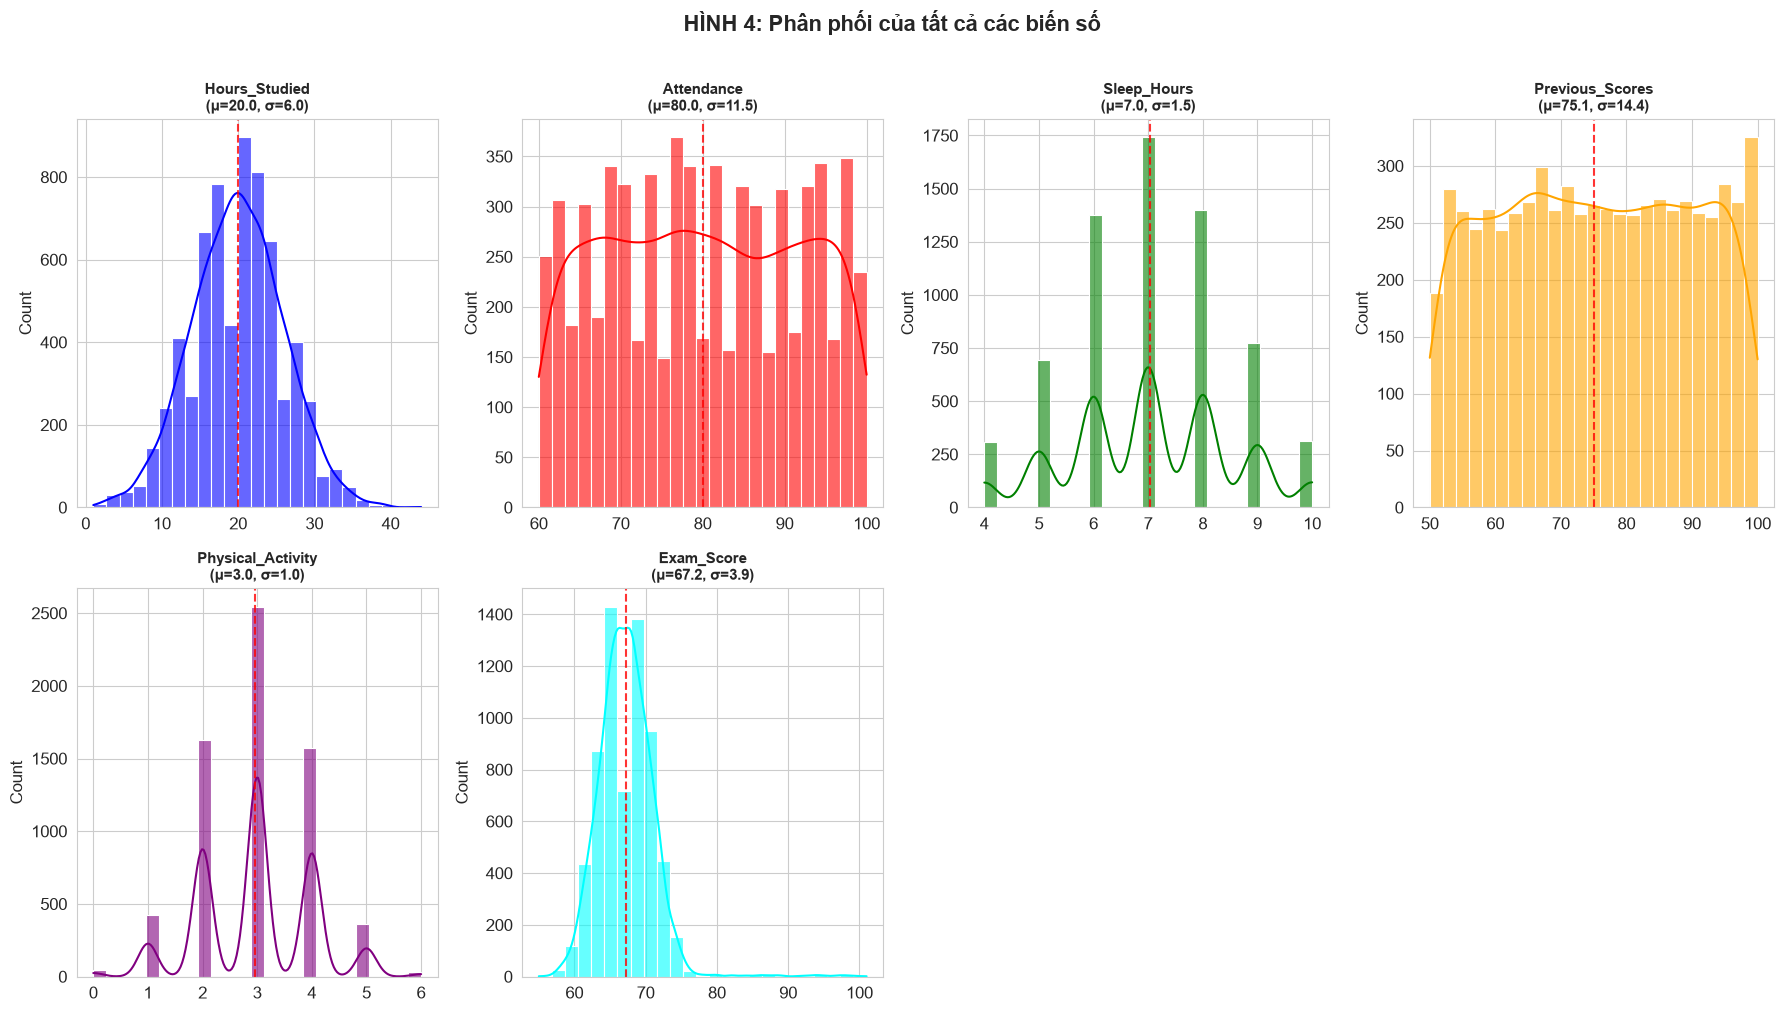

In [14]:
# HÌNH 4: Distribution plots cho các biến số
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

colors = ['blue', 'red', 'green', 'orange', 'purple', 'cyan', 'pink']

for i, col in enumerate(numeric_cols):
    if i < len(axes):
        sns.histplot(data=df, x=col, kde=True, color=colors[i % len(colors)], 
                     alpha=0.6, ax=axes[i], bins=25)
        axes[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, alpha=0.8)
        axes[i].set_title(f'{col}\n(μ={df[col].mean():.1f}, σ={df[col].std():.1f})', 
                         fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('HÌNH 4: Phân phối của tất cả các biến số', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 6. Nghiên cứu mối quan hệ và mô hình giữa các biến

### 6.1. So sánh điểm thi khi kết hợp các yếu tố

In [15]:
# 1. So sánh điểm thi khi kết hợp Giờ học và Động lực
hoc_it = df[df['Hours_Studied'] <= 20]
hoc_nhieu = df[df['Hours_Studied'] > 20]

print("Nhóm học <= 20 giờ/tuần - Điểm TB theo Động lực:")
print(hoc_it.groupby('Motivation_Level')['Exam_Score'].mean().round(2))

print("\nNhóm học > 20 giờ/tuần - Điểm TB theo Động lực:")
print(hoc_nhieu.groupby('Motivation_Level')['Exam_Score'].mean().round(2))

# 2. So sánh điểm thi khi kết hợp Điểm danh và Sự tham gia của phụ huynh
di_hoc_it = df[df['Attendance'] < 80]
di_hoc_nhieu = df[df['Attendance'] >= 80]

print("\nNhóm điểm danh < 80% - Điểm TB theo Phụ huynh:")
print(di_hoc_it.groupby('Parental_Involvement')['Exam_Score'].mean().round(2))

print("\nNhóm điểm danh >= 80% - Điểm TB theo Phụ huynh:")
print(di_hoc_nhieu.groupby('Parental_Involvement')['Exam_Score'].mean().round(2))

Nhóm học <= 20 giờ/tuần - Điểm TB theo Động lực:
Motivation_Level
High      66.52
Low       65.39
Medium    66.04
Name: Exam_Score, dtype: float64

Nhóm học > 20 giờ/tuần - Điểm TB theo Động lực:
Motivation_Level
High      69.19
Low       68.31
Medium    68.78
Name: Exam_Score, dtype: float64

Nhóm điểm danh < 80% - Điểm TB theo Phụ huynh:
Parental_Involvement
High      66.16
Low       64.34
Medium    65.15
Name: Exam_Score, dtype: float64

Nhóm điểm danh >= 80% - Điểm TB theo Phụ huynh:
Parental_Involvement
High      69.93
Low       68.22
Medium    69.05
Name: Exam_Score, dtype: float64


### 6.2. Phân tích tương quan chi tiết và kiểm định thống kê

In [16]:
from scipy.stats import f_oneway, ttest_ind

# 1. Xem mức độ tương quan của các biến số với Điểm thi
print("Mức độ tương quan với Exam_Score:")
print(df.corr(numeric_only=True)['Exam_Score'].sort_values(ascending=False).round(3))

# 2. Kiểm định ANOVA cho các biến có 3 mức (Low, Medium, High)
print("\nKiểm định ANOVA (p < 0.05 là có ảnh hưởng đến điểm thi):")
cac_bien = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income']

for col in cac_bien:
    low = df[df[col] == 'Low']['Exam_Score']
    med = df[df[col] == 'Medium']['Exam_Score']
    high = df[df[col] == 'High']['Exam_Score']
    
    stat, p = f_oneway(low, med, high)
    if p < 0.05:
        print(f"- {col}: p = {p:.5f} -> Có ảnh hưởng")
    else:
        print(f"- {col}: p = {p:.5f} -> Không ảnh hưởng")

# 3. Kiểm định T-test cho Giới tính (2 nhóm Male và Female)
nam = df[df['Gender'] == 'Male']['Exam_Score']
nu = df[df['Gender'] == 'Female']['Exam_Score']
stat, p_gender = ttest_ind(nam, nu)

if p_gender < 0.05:
    print(f"- Gender: p = {p_gender:.5f} -> Có ảnh hưởng")
else:
    print(f"- Gender: p = {p_gender:.5f} -> Không ảnh hưởng")

Mức độ tương quan với Exam_Score:
Exam_Score           1.000
Attendance           0.581
Hours_Studied        0.445
Previous_Scores      0.175
Physical_Activity    0.028
Sleep_Hours         -0.017
Name: Exam_Score, dtype: float64

Kiểm định ANOVA (p < 0.05 là có ảnh hưởng đến điểm thi):
- Parental_Involvement: p = 0.00000 -> Có ảnh hưởng
- Access_to_Resources: p = 0.00000 -> Có ảnh hưởng
- Motivation_Level: p = 0.00000 -> Có ảnh hưởng
- Family_Income: p = 0.00000 -> Có ảnh hưởng
- Gender: p = 0.86882 -> Không ảnh hưởng


### 6.3. Xây dựng mô hình hồi quy tuyến tính đơn giản

In [17]:
from sklearn.linear_model import LinearRegression

# 1. Lấy dữ liệu sạch và bỏ điểm thi ngoại lai ngoài khoảng [59, 75]
data = df.dropna().copy()
data = data[(data['Exam_Score'] >= 59) & (data['Exam_Score'] <= 75)]

# 2. Đổi 2 cột chữ sang số (Low=0, Medium=1, High=2)
muc_do = {'Low': 0, 'Medium': 1, 'High': 2}
data['Parental_Involvement'] = data['Parental_Involvement'].map(muc_do)
data['Access_to_Resources'] = data['Access_to_Resources'].map(muc_do)

# 3. Chọn 5 yếu tố quan trọng nhất (X) để dự đoán Điểm thi (y)
X = data[['Hours_Studied', 'Attendance', 'Previous_Scores', 'Parental_Involvement', 'Access_to_Resources']]
y = data['Exam_Score']

# 4. Tạo và chạy mô hình Hồi quy tuyến tính
model = LinearRegression()
model.fit(X, y)

# 5. In độ chính xác (R²) và hệ số tác động của từng yếu tố
print("Độ chính xác của mô hình (R²):", round(model.score(X, y) * 100, 1), "%")
print("\nHệ số tác động của từng yếu tố lên Điểm thi:")
for i in range(len(X.columns)):
    print("-", X.columns[i], ":", round(model.coef_[i], 3))

Độ chính xác của mô hình (R²): 85.8 %

Hệ số tác động của từng yếu tố lên Điểm thi:
- Hours_Studied : 0.292
- Attendance : 0.199
- Previous_Scores : 0.047
- Parental_Involvement : 0.981
- Access_to_Resources : 0.963


## 7. Kết luận tổng hợp

**1. Tổng quan dữ liệu:**
- Tập dữ liệu gồm 6,607 sinh viên với 16 biến (6 biến số, 10 biến phân loại).
- Dữ liệu không có dòng trùng lặp; chỉ có 2 cột bị thiếu dữ liệu nhẹ (`Teacher_Quality`: 78 dòng ~1.18%, `Parental_Education_Level`: 90 dòng ~1.36%).
- Phát hiện 1 giá trị bất thường vượt thang điểm 100 (`Exam_Score = 101`).

**2. Các yếu tố ảnh hưởng mạnh nhất đến Điểm thi:**
- **Tỷ lệ điểm danh (`Attendance`, r ≈ 0.58)** và **Số giờ học (`Hours_Studied`, r ≈ 0.45)** là hai yếu tố có mối liên hệ chặt chẽ nhất.
- Nhóm sinh viên học nhiều (> 20 giờ/tuần) kết hợp động lực cao, hoặc đi học đầy đủ (>= 80%) và được phụ huynh quan tâm có điểm trung bình cao hơn hẳn.
- Kiểm định ANOVA cho thấy sự tham gia của phụ huynh, tiếp cận tài nguyên, động lực và thu nhập gia đình đều có ảnh hưởng rõ rệt (p < 0.05); riêng `Gender` không tạo ra sự khác biệt đáng kể.

**3. Mô hình dự đoán (Hồi quy tuyến tính):**
- Chỉ với 5 yếu tố chính (`Hours_Studied`, `Attendance`, `Previous_Scores`, `Parental_Involvement`, `Access_to_Resources`) sau khi xử lý dữ liệu sạch và bỏ điểm ngoại lai ngoài khoảng `[59, 75]`, mô hình đạt độ chính xác **R² ≈ 85.8%**.

**4. Khuyến nghị:**
- Sinh viên cần duy trì tỷ lệ đi học đầy đủ và tăng thời gian tự học.
- Gia đình và nhà trường cần tăng cường hỗ trợ tài nguyên học tập và động viên sinh viên.

In [18]:
print("Hoàn tất toàn bộ quá trình phân tích!")

Hoàn tất toàn bộ quá trình phân tích!
